In [2]:
# importing the required modules
import pandas as pd 
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from sklearn.model_selection import train_test_split

In [3]:
# load thee dataset

df = pd.read_csv("car_fuel_efficiency_practice.csv")

In [4]:
df.head()

,VehicleAgeYears,EngineSizeL,OdometerKm,FuelEfficiencyKmPerL
0,1,1.2,12000,20.8
1,2,1.0,24500,22.4
2,3,1.5,38200,18.9
3,4,1.3,51700,19.8
4,5,1.8,64300,16.2


In [5]:
# checking for the correlation 
df.corr()

,VehicleAgeYears,EngineSizeL,OdometerKm,FuelEfficiencyKmPerL
VehicleAgeYears,1.000000,0.365276,0.999007,-0.599896
EngineSizeL,0.365276,1.000000,0.367361,-0.943679
OdometerKm,0.999007,0.367361,1.000000,-0.603028
FuelEfficiencyKmPerL,-0.599896,-0.943679,-0.603028,1.000000


Negativtly highly corr related 

In [6]:
x=df.drop(columns="FuelEfficiencyKmPerL")
y=df["FuelEfficiencyKmPerL"]

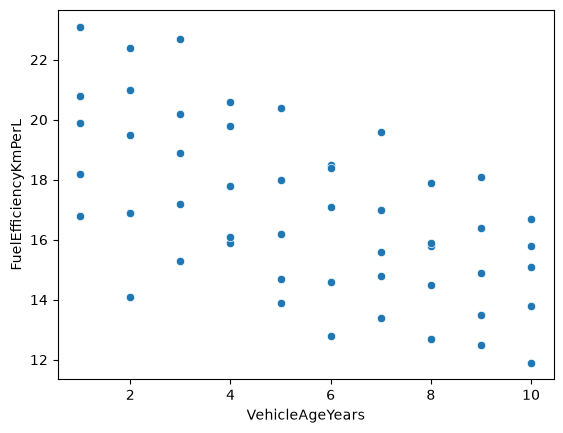

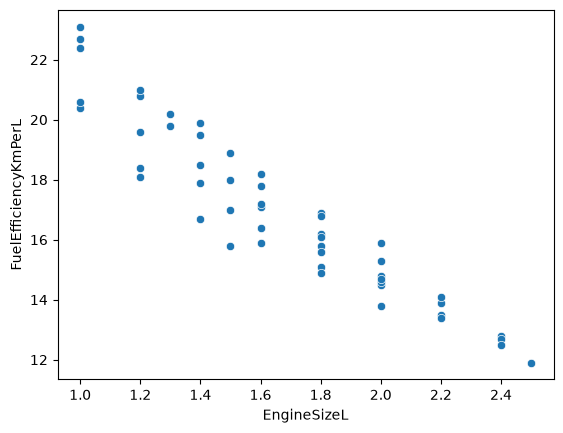

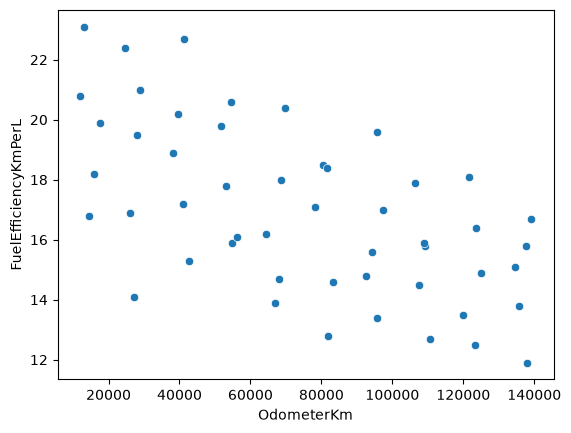

In [7]:
# graph
import matplotlib.pyplot as plt
import seaborn as sns
for column in df.columns:
    if column == "FuelEfficiencyKmPerL":
        continue
    sns.scatterplot(df,x=df[column],y=y)
    plt.show()

In [8]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.8,random_state=40)


In [9]:
# model selction and fit 
model=LinearRegression()
model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
model.coef_

array([ 3.94689724e-01, -5.73375277e+00, -4.86076819e-05])

In [11]:
model.intercept_

np.float64(28.008327247420752)

In [12]:
# model prediction
ytrain_predict = model.predict(xtrain)

In [13]:
# model evaluation
print("MSE: ",mean_squared_error(ytrain,ytrain_predict))
print("RMSE: ",np.sqrt(mean_squared_error(ytrain,ytrain_predict)))
print("MAE :",mean_absolute_error(ytrain,ytrain_predict))


MSE:  0.2627805476360627
RMSE:  0.5126212516430261
MAE : 0.41617391596857534


these errors are low compare to the traget 

these error suggest the model may perform well .. 

In [14]:
# accuracy for train data
r2_score(ytrain,ytrain_predict)

0.9690855279725287

the model is too good , and the model will able to capture the test data pattern

In [15]:
# model testing / evalutation 

ytest_predict=model.predict(xtest)

In [16]:
# accuracy for test data
r2_score(ytest,ytest_predict)

0.9440701277876484

this indicates the model is ready to predict the real time value

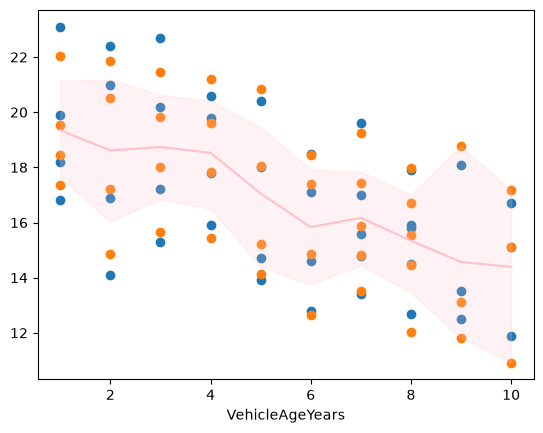

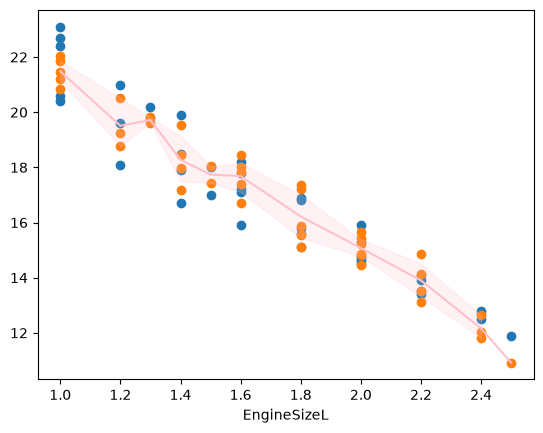

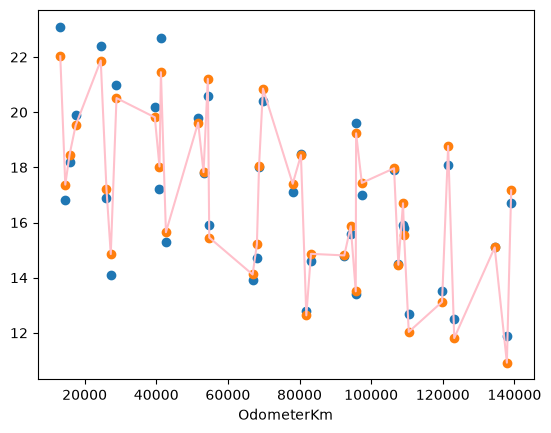

In [17]:
# grpah to understand 

for column in xtrain.columns:    
    plt.scatter(x=xtrain[column],y=ytrain)
    plt.scatter(x=xtrain[column],y=ytrain_predict)
    sns.lineplot(x=xtrain[column],y=ytrain_predict,color="pink")
    plt.xlabel(column)
    plt.show()

## Conclusion

The linear regression model successfully learned the relationship between the available car features and fuel efficiency. The training and test metrics show that the model generalizes well:

- Training R?: about 0.969
- Test R?: about 0.944
- Training RMSE: about 0.513 km/L
- Test RMSE: about 0.497 km/L

These values indicate that the predicted fuel efficiency values are close to the real values, so the model is reliable for this dataset. It is a good example of how a simple linear regression model can perform well when the relationship between features and target is mostly linear.
